In [5]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from numpy import array
!pip install keras==2.10.0
!pip install tensorflow==2.10.0

from keras.preprocessing.text import one_hot, Tokenizer
from tensorflow.keras.utils import pad_sequences
from keras.models import Sequential
from keras.layers import Activation, Dropout, Dense

from keras.layers import Flatten, GlobalMaxPooling1D,Embedding, Conv1D, LSTM
from sklearn.model_selection import train_test_split


In [7]:
twr = pd.read_csv('cleaned_twitter_training.csv')
twr.shape

(71981, 4)

In [8]:
twr.head()

,tweet_id,game_title,sentiment,tweet_text
0,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
1,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
2,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
3,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
4,2401,Borderlands,Positive,im getting into borderlands and i can murder y...


In [10]:
twr.isnull().values.any()

False

In [11]:
import seaborn as sns

<Axes: xlabel='sentiment', ylabel='count'>

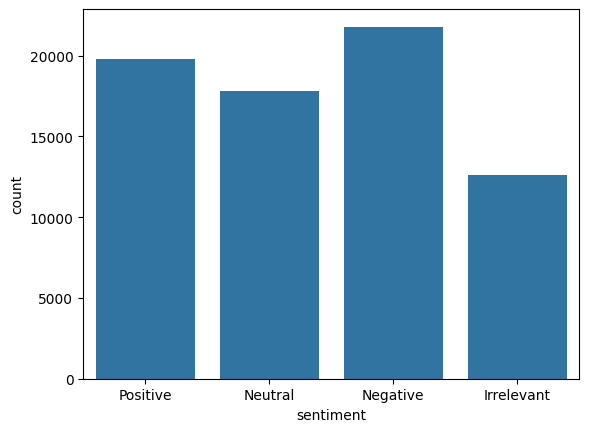

In [13]:
sns.countplot(x='sentiment', data=twr)

In [18]:
twr["tweet_text"][2]

'im coming on borderlands and i will murder you all,'

In [20]:
TAG_RE = re.compile(r'<[^>]+>')

def remove_tags(text):
    return TAG_RE.sub('', text)


In [22]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [24]:
def preprocess_text(sen):
    # Removing html tags
    sentence = sen.lower()
    sentence = remove_tags(sentence)
    # Remove punctuations and numbers
    sentence = re.sub('[^a-zA-Z]', ' ', sentence)
    sentence = re.sub(r"\s+[a-zA-Z]\s+", ' ', sentence)
    sentence = re.sub(r'\s+', ' ', sentence)
    pattern = re.compile(r'\b(' + r'|'.join(stopwords.words('english')) + r')\b\s*')
    sentence = pattern.sub('', sentence)
    return sentence

In [28]:
X = []
sentences = list(twr['tweet_text'])
for sen in sentences:
    X.append(preprocess_text(sen))

In [32]:
X[1]

'im getting borderlands kill '

In [34]:
y = twr['sentiment']
y = np.array(list(map(lambda x: 1 if x == "Positive" else 0, y)))

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [40]:
X_train = [str(x) for x in X_train] # Ensure all elements in X_train are strings
word_tokenizer = Tokenizer()
word_tokenizer.fit_on_texts(X_train)
X_train = word_tokenizer.texts_to_sequences(X_train)
X_test = [str(x) for x in X_test] # Ensure all elements in X_test are strings before tokenization
X_test = word_tokenizer.texts_to_sequences(X_test)

In [42]:
vocab_length = len(word_tokenizer.word_index) + 1
vocab_length

27946

In [45]:
maxlen = 100
X_train = pad_sequences(X_train, padding='post', maxlen=maxlen)
X_test = pad_sequences(X_test, padding='post', maxlen=maxlen)

In [46]:
from numpy import array
from numpy import asarray
from numpy import zeros

In [49]:
embedded_dictionary = dict()
glove_file = open('glove.6B.100d.txt', encoding='utf8')
for line in glove_file:
    records = line.split()
    word = records[0]
    vector_dimensions = asarray(records[1:], dtype='float32')
    embedded_dictionary[word] = vector_dimensions
glove_file.close()

In [51]:
embedding_matrix = zeros((vocab_length, 100))
for word, index in word_tokenizer.word_index.items():
    embedding_vector = embedded_dictionary.get(word)
    if embedding_vector is not None:
        embedding_matrix[index] = embedding_vector

In [53]:
embedding_matrix.shape


(27946, 100)

In [55]:
#Neural Network architecture
snn_model = Sequential()
emebedding_layer = Embedding(vocab_length, 100, weights=[embedding_matrix], input_length=maxlen , trainable=False)
snn_model.add(emebedding_layer)
snn_model.add(Flatten())
snn_model.add(Dense(1, activation='sigmoid'))

In [56]:
#Model Compilation
snn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['acc'])
print(snn_model.summary())


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_1 (Embedding)     (None, 100, 100)          2794600   
                                                                 
 flatten (Flatten)           (None, 10000)             0         
                                                                 
 dense (Dense)               (None, 1)                 10001     
                                                                 
Total params: 2,804,601
Trainable params: 10,001
Non-trainable params: 2,794,600
_________________________________________________________________
None


In [59]:
#Model Training
snn_model.fit(X_train, y_train, batch_size=128, epochs=10, verbose=1, validation_split=0.2)


Epoch 1/10
360/360 [==============================] - 2s 5ms/step - loss: 0.5197 - acc: 0.7448 - val_loss: 0.5522 - val_acc: 0.7345
Epoch 2/10
360/360 [==============================] - 1s 4ms/step - loss: 0.5189 - acc: 0.7470 - val_loss: 0.5529 - val_acc: 0.7318
Epoch 3/10
360/360 [==============================] - 2s 6ms/step - loss: 0.5188 - acc: 0.7465 - val_loss: 0.5538 - val_acc: 0.7353
Epoch 4/10
360/360 [==============================] - 2s 7ms/step - loss: 0.5178 - acc: 0.7465 - val_loss: 0.5519 - val_acc: 0.7339
Epoch 5/10
360/360 [==============================] - 2s 4ms/step - loss: 0.5165 - acc: 0.7477 - val_loss: 0.5556 - val_acc: 0.7366
Epoch 6/10
360/360 [==============================] - 1s 4ms/step - loss: 0.5159 - acc: 0.7483 - val_loss: 0.5518 - val_acc: 0.7362
Epoch 7/10
360/360 [==============================] - 1s 4ms/step - loss: 0.5159 - acc: 0.7471 - val_loss: 0.5536 - val_acc: 0.7351
Epoch 8/10
360/360 [==============================] - 1s 4ms/step - loss: 0.

In [61]:
#Model Training
snn_model_history = snn_model.fit(X_train, y_train, batch_size=128, epochs=10, verbose=1, validation_split=0.2)

Epoch 1/10
360/360 [==============================] - 3s 7ms/step - loss: 0.5085 - acc: 0.7517 - val_loss: 0.5595 - val_acc: 0.7265
Epoch 2/10
360/360 [==============================] - 4s 12ms/step - loss: 0.5080 - acc: 0.7503 - val_loss: 0.5554 - val_acc: 0.7307
Epoch 3/10
360/360 [==============================] - 2s 5ms/step - loss: 0.5082 - acc: 0.7516 - val_loss: 0.5572 - val_acc: 0.7320
Epoch 4/10
360/360 [==============================] - 1s 4ms/step - loss: 0.5079 - acc: 0.7527 - val_loss: 0.5559 - val_acc: 0.7314
Epoch 5/10
360/360 [==============================] - 1s 4ms/step - loss: 0.5080 - acc: 0.7517 - val_loss: 0.5552 - val_acc: 0.7326
Epoch 6/10
360/360 [==============================] - 1s 4ms/step - loss: 0.5068 - acc: 0.7522 - val_loss: 0.5592 - val_acc: 0.7309
Epoch 7/10
360/360 [==============================] - 1s 3ms/step - loss: 0.5070 - acc: 0.7529 - val_loss: 0.5556 - val_acc: 0.7341
Epoch 8/10
360/360 [==============================] - 1s 4ms/step - loss: 0

In [62]:
#Predictions on the Test set
score = snn_model.evaluate(X_test, y_test, verbose=1)
print("Test Score:", score[0])
print("Test Accuracy:", score[1])

450/450 [==============================] - 1s 3ms/step - loss: 0.5594 - acc: 0.7253
Test Score: 0.5594140887260437
Test Accuracy: 0.7252900004386902


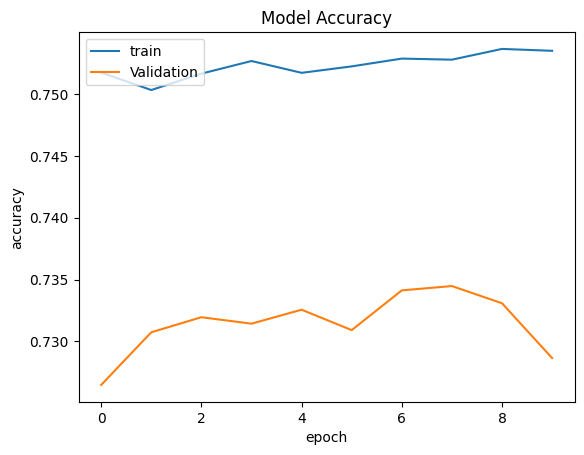

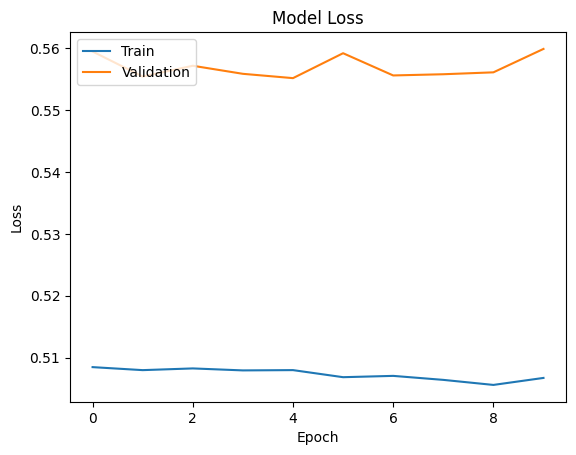

In [65]:
#Performance Charts
import matplotlib.pyplot as plt
plt.plot(snn_model_history.history['acc'])
plt.plot(snn_model_history.history['val_acc'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'Validation'], loc='upper left')
plt.show()
plt.plot(snn_model_history.history['loss'])
plt.plot(snn_model_history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [66]:
#CNN Architecture:
cnn_model = Sequential()
embeddign_layer = Embedding(vocab_length, 100, weights=[embedding_matrix], input_length=maxlen , trainable=False)
cnn_model.add(embeddign_layer)
cnn_model.add((Conv1D(120, 6, activation='relu')))
cnn_model.add(GlobalMaxPooling1D())
cnn_model.add(Dense(1, activation='sigmoid'))

In [67]:
#Model Compilation:
cnn_model.compile(optimizer='adamax', loss='binary_crossentropy', metrics=['acc'])
print(cnn_model.summary())

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_2 (Embedding)     (None, 100, 100)          2794600   
                                                                 
 conv1d (Conv1D)             (None, 95, 120)           72120     
                                                                 
 global_max_pooling1d (Globa  (None, 120)              0         
 lMaxPooling1D)                                                  
                                                                 
 dense_1 (Dense)             (None, 1)                 121       
                                                                 
Total params: 2,866,841
Trainable params: 72,241
Non-trainable params: 2,794,600
_________________________________________________________________
None


In [68]:
#Model Training:
cnn_model_history = cnn_model.fit(X_train, y_train, batch_size=120, epochs=10, verbose=1, validation_split=0.2)

Epoch 1/10
384/384 [==============================] - 45s 113ms/step - loss: 0.5639 - acc: 0.7271 - val_loss: 0.5442 - val_acc: 0.7379
Epoch 2/10
384/384 [==============================] - 46s 121ms/step - loss: 0.5291 - acc: 0.7410 - val_loss: 0.5278 - val_acc: 0.7465
Epoch 3/10
384/384 [==============================] - 43s 113ms/step - loss: 0.5056 - acc: 0.7536 - val_loss: 0.5398 - val_acc: 0.7360
Epoch 4/10
384/384 [==============================] - 42s 109ms/step - loss: 0.4839 - acc: 0.7695 - val_loss: 0.5072 - val_acc: 0.7533
Epoch 5/10
384/384 [==============================] - 42s 109ms/step - loss: 0.4652 - acc: 0.7795 - val_loss: 0.4940 - val_acc: 0.7650
Epoch 6/10
384/384 [==============================] - 44s 113ms/step - loss: 0.4471 - acc: 0.7903 - val_loss: 0.4859 - val_acc: 0.7715
Epoch 7/10
384/384 [==============================] - 43s 112ms/step - loss: 0.4297 - acc: 0.8037 - val_loss: 0.4777 - val_acc: 0.7772
Epoch 8/10
384/384 [==============================] - 4

In [69]:
#Prediction:
score = cnn_model.evaluate(X_test, y_test, verbose=1)
print("Test Score:", score[0])
print("Test Accuracy:", score[1])


450/450 [==============================] - 8s 18ms/step - loss: 0.4545 - acc: 0.7889
Test Score: 0.4544593095779419
Test Accuracy: 0.7889143824577332


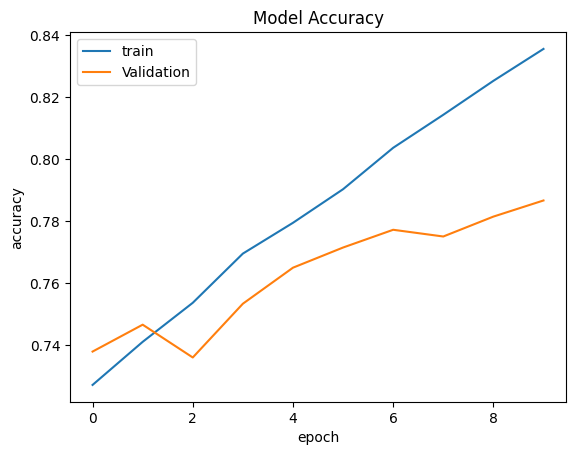

In [70]:
#Performance Charts:
import matplotlib.pyplot as plt
plt.plot(cnn_model_history.history['acc'])
plt.plot(cnn_model_history.history['val_acc'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'Validation'], loc='upper left')
plt.show()



In [72]:
from keras.layers import LSTM


In [73]:
#LSTM ARCHITECTURE:
lstm_model = Sequential()

# Adding the Embedding layer
# Assuming 'embedding_layer' is pre-trained and you want to add it directly,
# make sure to set its 'trainable' flag accordingly.
lstm_model.add(Embedding(vocab_length, 100, input_length=maxlen, trainable=False))

# First LSTM layer
# Return sequences to pass outputs to the next LSTM layer
lstm_model.add(LSTM(133, return_sequences=True))

# Second LSTM layer
# Also returning sequences to feed into the final LSTM layer
lstm_model.add(LSTM(133, return_sequences=True))

# Third LSTM layer
# No need to return sequences as this is the final LSTM layer before the output layer
lstm_model.add(LSTM(133))

# Output layer with sigmoid activation for binary classification
lstm_model.add(Dense(1, activation='sigmoid'))

# Compile the model (assuming a binary classification problem)
lstm_model.compile(optimizer='adamax', loss='binary_crossentropy', metrics=['accuracy'])

# Summary of the model to see the stack of layers and parameters
lstm_model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_3 (Embedding)     (None, 100, 100)          2794600   
                                                                 
 lstm (LSTM)                 (None, 100, 133)          124488    
                                                                 
 lstm_1 (LSTM)               (None, 100, 133)          142044    
                                                                 
 lstm_2 (LSTM)               (None, 133)               142044    
                                                                 
 dense_2 (Dense)             (None, 1)                 134       
                                                                 
Total params: 3,203,310
Trainable params: 408,710
Non-trainable params: 2,794,600
_________________________________________________________________


In [75]:
#Model Traning:
lstm_model_history = lstm_model.fit(X_train, y_train, batch_size=140, epochs=2, verbose=1, validation_split=0.2)



Epoch 1/2
330/330 [==============================] - 538s 2s/step - loss: 0.5895 - accuracy: 0.7242 - val_loss: 0.5843 - val_accuracy: 0.7290
Epoch 2/2
330/330 [==============================] - 480s 1s/step - loss: 0.5894 - accuracy: 0.7242 - val_loss: 0.5843 - val_accuracy: 0.7290


In [76]:
#Predictions on the Test set:
score = lstm_model.evaluate(X_test, y_test, verbose=1)
print("Test Score:", score[0])
print("Test Accuracy:", score[1])

450/450 [==============================] - 97s 215ms/step - loss: 0.5901 - accuracy: 0.7232
Test Score: 0.5900824069976807
Test Accuracy: 0.7232062220573425


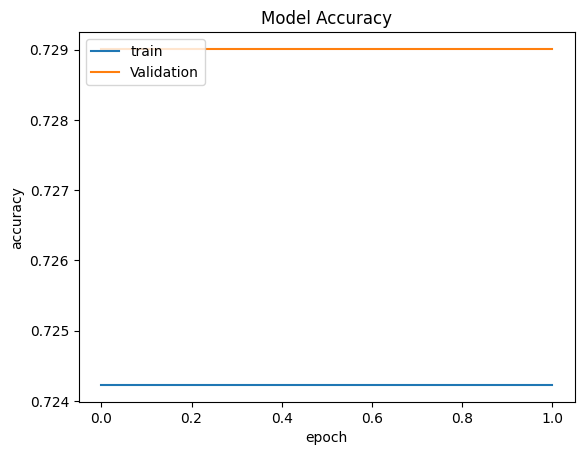

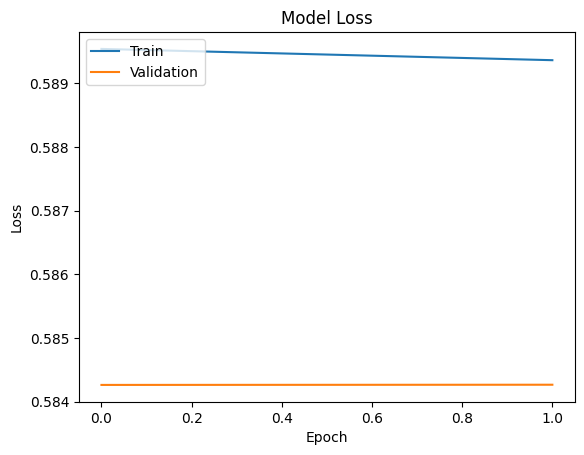

In [77]:
#Model Performance Charts:
import matplotlib.pyplot as plt
plt.plot(lstm_model_history.history['accuracy'])
plt.plot(lstm_model_history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'Validation'], loc='upper left')
plt.show()
plt.plot(lstm_model_history.history['loss'])
plt.plot(lstm_model_history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()